# Exploratory Data Analysis: UCI Bank Marketing

**BITS Pilani · M.Tech AIML · Machine Learning, Assignment 2**
**Student ID: 2026AJ05200**

**Goal of this notebook.** Understand the data before modelling. We want to know the size and types of the data, data quality (missing values, `"unknown"` codes, duplicates, outliers), how imbalanced the target is, and which features relate to subscription. The findings drive the preprocessing and evaluation choices in `src/`.

**Dataset.** UCI Bank Marketing, `bank-full.csv` (https://archive.ics.uci.edu/dataset/222/bank+marketing). These are direct-marketing phone campaigns run by a Portuguese bank (May 2008 – Nov 2010). Target `y`: did the client subscribe to a term deposit (`yes` / `no`)?

| Section | Content |
|---|---|
| 1 | Setup and loading |
| 2 | Overview, shape, data types, feature dictionary |
| 3 | Missing values and `"unknown"` categories |
| 4 | Duplicates |
| 5 | Target distribution |
| 6 | Numerical features: statistics, distributions, boxplots, IQR outliers |
| 7 | Categorical features: frequencies and subscription rates |
| 8 | Correlation heatmap |
| 9 | Why `duration` is excluded |
| 10 | Observations and modelling implications |

## 1. Setup and loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

PALETTE = {"no": "#94a3b8", "yes": "#2563eb"}
ACCENT = "#2563eb"

# Works whether the notebook is run from the repo root or from notebooks/
DATA_PATH = next(p for p in [Path("data/bank-full.csv"), Path("../data/bank-full.csv")] if p.exists())
df = pd.read_csv(DATA_PATH, sep=";")   # the UCI file is semicolon-separated

NUMERICAL = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
TARGET = "y"
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

print(f"Loaded {DATA_PATH} -> {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded ../data/bank-full.csv -> 45,211 rows x 17 columns


## 2. Dataset overview

In [2]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
n_rows, n_cols = df.shape
print(f"Instances           : {n_rows:,}  (assignment minimum: 500)")
print(f"Input features      : {n_cols - 1}  (assignment minimum: 12)")
print(f"Features used later : {n_cols - 2}  (after dropping 'duration', see Section 9)")
print(f"Numerical / categorical inputs: {len(NUMERICAL)} / {len(CATEGORICAL)}")

Instances           : 45,211  (assignment minimum: 500)
Input features      : 16  (assignment minimum: 12)
Features used later : 15  (after dropping 'duration', see Section 9)
Numerical / categorical inputs: 7 / 9


In [4]:
dictionary = {
    "age": "Client age (years)",
    "job": "Type of job",
    "marital": "Marital status ('divorced' includes widowed)",
    "education": "Education level",
    "default": "Has credit in default?",
    "balance": "Average yearly balance (EUR)",
    "housing": "Has a housing loan?",
    "loan": "Has a personal loan?",
    "contact": "Contact communication type",
    "day": "Last contact day of the month",
    "month": "Last contact month of year",
    "duration": "Last contact duration (seconds), known only AFTER the call",
    "campaign": "Contacts made during this campaign (incl. last)",
    "pdays": "Days since last contact in a previous campaign (-1 = never contacted)",
    "previous": "Contacts made before this campaign",
    "poutcome": "Outcome of the previous campaign",
    "y": "TARGET: subscribed to a term deposit?",
}
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "kind": ["target" if c == TARGET else ("numerical" if c in NUMERICAL else "categorical") for c in df.columns],
    "n_unique": df.nunique(),
    "example": df.iloc[0],
    "description": pd.Series(dictionary),
})
overview

,dtype,kind,n_unique,example,description
age,int64,numerical,77,58,Client age (years)
job,str,categorical,12,management,Type of job
marital,str,categorical,3,married,Marital status ('divorced' includes widowed)
education,str,categorical,4,tertiary,Education level
default,str,categorical,2,no,Has credit in default?
balance,int64,numerical,7168,2143,Average yearly balance (EUR)
housing,str,categorical,2,yes,Has a housing loan?
loan,str,categorical,2,no,Has a personal loan?
contact,str,categorical,3,unknown,Contact communication type
day,int64,numerical,31,5,Last contact day of the month


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


## 3. Missing values and `"unknown"` categories
The file has no `NaN` cells. Missing information is instead stored as the text `"unknown"` in some categorical columns. We check both.

In [6]:
nan_counts = df.isna().sum()
print(f"Total NaN cells: {int(nan_counts.sum())}")

unknown = pd.DataFrame({
    "unknown_count": [(df[c] == "unknown").sum() for c in CATEGORICAL],
}, index=CATEGORICAL)
unknown["unknown_pct"] = (unknown["unknown_count"] / len(df) * 100).round(2)
unknown = unknown[unknown["unknown_count"] > 0].sort_values("unknown_pct", ascending=False)
unknown

Total NaN cells: 0


,unknown_count,unknown_pct
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


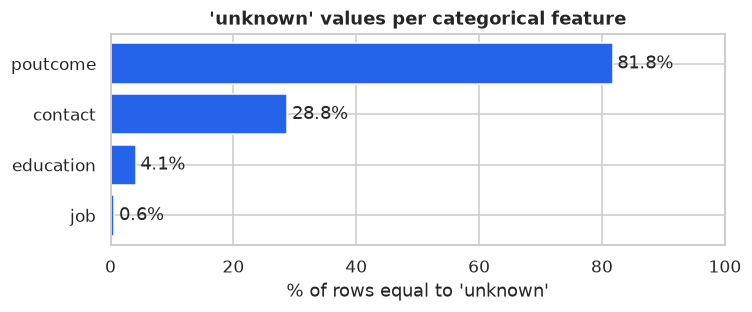

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(unknown.index[::-1], unknown["unknown_pct"][::-1], color=ACCENT)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("% of rows equal to 'unknown'")
ax.set_title("'unknown' values per categorical feature")
ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

In [8]:
# Is poutcome='unknown' the same thing as 'never contacted before' (pdays == -1)?
never = df["pdays"] == -1
print(f"pdays == -1                       : {never.sum():,}")
print(f"previous == 0                     : {(df['previous'] == 0).sum():,}")
print(f"poutcome == 'unknown'             : {(df['poutcome'] == 'unknown').sum():,}")
print(f"poutcome 'unknown' AND pdays == -1: {((df['poutcome'] == 'unknown') & never).sum():,}")

pdays == -1                       : 36,954
previous == 0                     : 36,954
poutcome == 'unknown'             : 36,959
poutcome 'unknown' AND pdays == -1: 36,954


**Observation.** There are no `NaN` cells. `"unknown"` appears in four columns:
- `poutcome` (81.75%) almost entirely means "no previous campaign". All 36,954 clients with `pdays = -1` have `poutcome = "unknown"`, and `previous = 0` for the same 36,954 clients.
- `contact` (28.80%) is genuinely missing information.
- `education` (4.11%) and `job` (0.64%) are small.

**Decision.** Keep `"unknown"` as its own category; do not drop or impute it. It carries information: for example, `contact = "unknown"` has a much lower subscription rate (Section 7). The pipeline still includes median and most-frequent imputers, so that a future file with real blanks does not break the model.

## 4. Duplicates

In [9]:
n_dup = df.duplicated().sum()
n_dup_features = df.drop(columns=TARGET).duplicated().sum()
print(f"Fully duplicated rows            : {n_dup}")
print(f"Duplicated on input features only: {n_dup_features}")

Fully duplicated rows            : 0
Duplicated on input features only: 0


**Observation.** There are no duplicated rows, so there is no risk of the same record appearing in both train and test.

## 5. Target distribution

,count,percent
y,,
no,39922,88.3
yes,5289,11.7


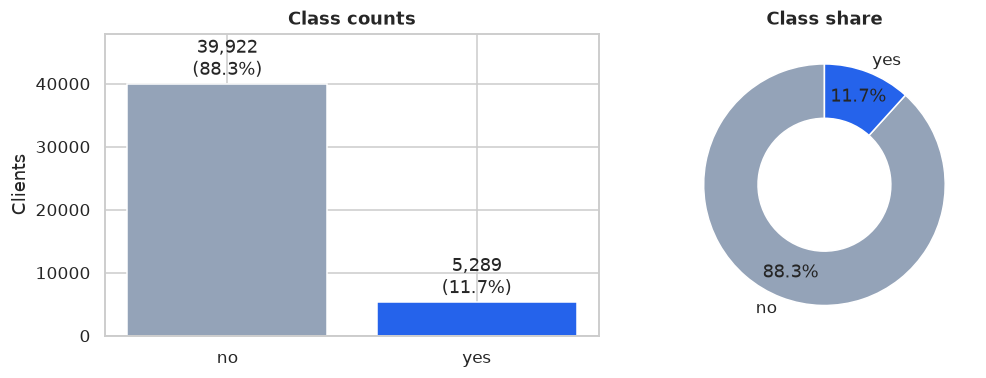

Majority-class baseline accuracy (always predict 'no'): 88.30%


In [10]:
counts = df[TARGET].value_counts()
share = df[TARGET].value_counts(normalize=True) * 100
target_tbl = pd.DataFrame({"count": counts, "percent": share.round(2)})
display(target_tbl)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bars = axes[0].bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
axes[0].bar_label(bars, labels=[f"{c:,}\n({p:.1f}%)" for c, p in zip(counts, share)], padding=2)
axes[0].set_title("Class counts"); axes[0].set_ylabel("Clients"); axes[0].set_ylim(0, counts.max() * 1.2)
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=[PALETTE[k] for k in counts.index],
            startangle=90, pctdistance=0.78, wedgeprops={"width": 0.45})
axes[1].set_title("Class share")
plt.tight_layout(); plt.show()

print(f"Majority-class baseline accuracy (always predict 'no'): {share['no']:.2f}%")

**Observation.** The classes are imbalanced: 39,922 `no` (88.30%) and 5,289 `yes` (11.70%), about 7.5 : 1.

**Implications:**
- A useless model that always says `no` already gets **88.3% accuracy**, so accuracy alone is misleading. We compare models on **MCC, F1 and ROC-AUC**, with `yes` as the positive class.
- We use a **stratified** 80:20 split, so train and test both keep the 11.7% positive rate.
- We use `class_weight="balanced"` for the models that support it (Logistic Regression, Decision Tree, SVM).

## 6. Numerical features

### 6.1 Descriptive statistics

In [11]:
desc = df[NUMERICAL].describe().T
desc["skew"] = df[NUMERICAL].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,0.09
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0,3.14
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,41.85


In [12]:
# Median of each numerical feature for each class
df.groupby(TARGET)[NUMERICAL].median().T.rename(columns={"no": "median | y=no", "yes": "median | y=yes"})

y,median | y=no,median | y=yes
age,39.0,38.0
balance,417.0,733.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


### 6.2 Distributions (by target)

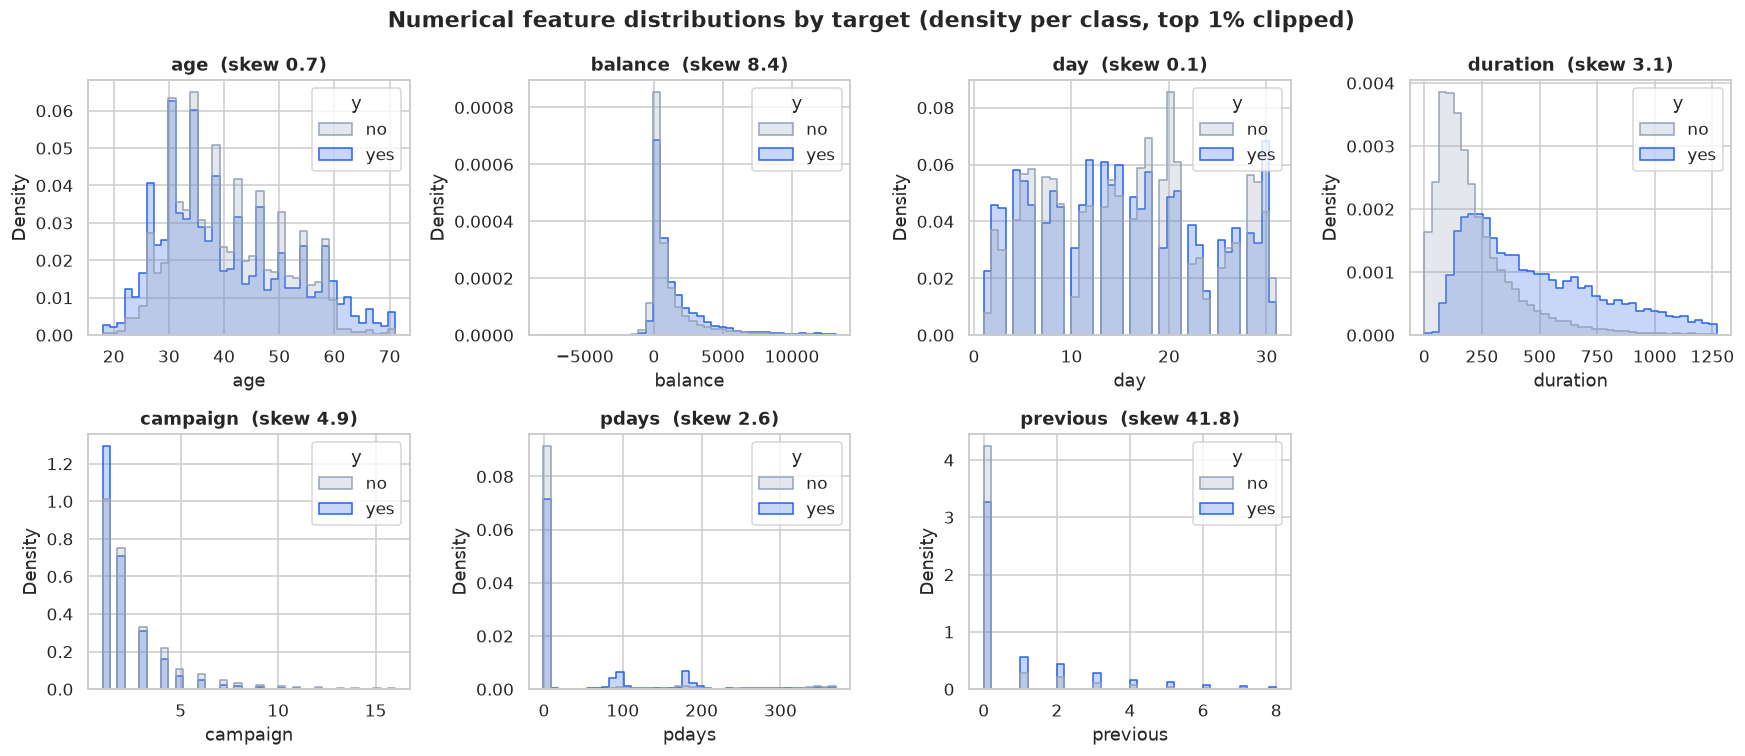

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, NUMERICAL):
    data = df[col]
    # Clip the extreme 1% tail for readability only; statistics above use the full data
    hi = data.quantile(0.99)
    sns.histplot(data=df[data <= hi], x=col, hue=TARGET, palette=PALETTE, bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"{col}  (skew {data.skew():.1f})")
axes.flat[-1].axis("off")
fig.suptitle("Numerical feature distributions by target (density per class, top 1% clipped)", fontweight="bold")
plt.tight_layout(); plt.show()

### 6.3 Boxplots (by target)

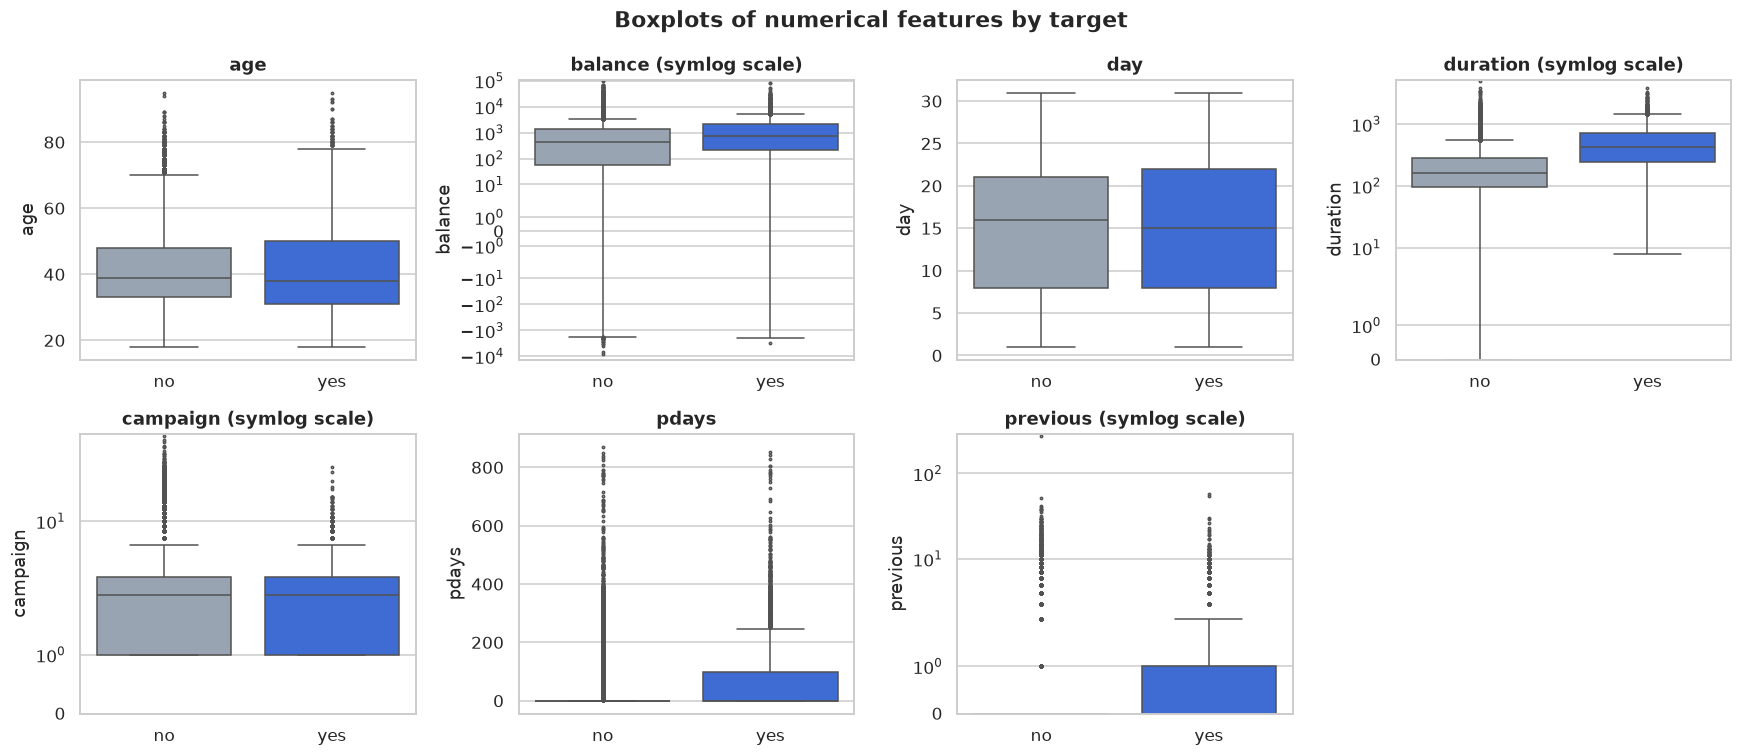

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, NUMERICAL):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False,
                order=["no", "yes"], fliersize=1.5, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
    if col in ("balance", "duration", "campaign", "previous"):
        ax.set_yscale("symlog")
        ax.set_title(f"{col} (symlog scale)")
        if col != "balance":
            ax.set_ylim(bottom=0)
axes.flat[-1].axis("off")
fig.suptitle("Boxplots of numerical features by target", fontweight="bold")
plt.tight_layout(); plt.show()

### 6.4 IQR-based outlier analysis

In [15]:
rows = []
for col in NUMERICAL:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lo) | (df[col] > hi)
    rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lo, "upper_fence": hi,
                 "n_outliers": int(mask.sum()), "pct_outliers": round(mask.mean() * 100, 2),
                 "yes_rate_in_outliers_%": round(df.loc[mask, TARGET].eq("yes").mean() * 100, 1) if mask.any() else np.nan})
outliers = pd.DataFrame(rows).set_index("feature")
outliers

,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,pct_outliers,yes_rate_in_outliers_%
feature,,,,,,,,
age,33.0,48.0,15.0,10.5,70.5,487,1.08,44.8
balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46,16.2
day,8.0,21.0,13.0,-11.5,40.5,0,0.00,NaN
duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16,51.0
campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78,5.3
pdays,-1.0,-1.0,0.0,-1.0,-1.0,8257,18.26,23.1
previous,0.0,0.0,0.0,0.0,0.0,8257,18.26,23.1


**Observations (numerical):**
- **`balance`** is very right-skewed: median EUR 448, maximum EUR 102,127. 3,766 clients have a negative balance, and 10.46% of rows fall outside the IQR fences. Subscribers have a higher median balance (733 vs 417).
- **`campaign`** is right-skewed: median 2, maximum 63, and 6.78% IQR outliers. Repeated calls do not help: clients called once subscribe at 14.6%, while those called more than 10 times subscribe at only 3.9% (1,196 clients).
- **`pdays` and `previous`** are 0 / -1 for 81.74% of clients, so the IQR is zero. That makes *every* previously contacted client an "outlier" (18.26%). These are real values, not errors: previously contacted clients subscribe at 23.1%, versus 9.2% for clients never contacted.
- **`age`** ranges from 18 to 95; only 1.08% of values are outliers (above 70.5). Subscription is U-shaped by age (Section 7.3).
- **`day`** is roughly uniform, has no outliers, and is barely related to the target.

**Decision.** Keep the outliers. They are genuine customer behaviour, not data-entry errors, and removing them would delete exactly the informative rows (e.g. previous-campaign contacts). Instead we use **StandardScaler**, fitted on the training split only, so that scale-sensitive models (Logistic Regression, KNN, SVM) see comparable feature ranges. Tree models are unaffected by scaling.

## 7. Categorical features

### 7.1 Frequencies

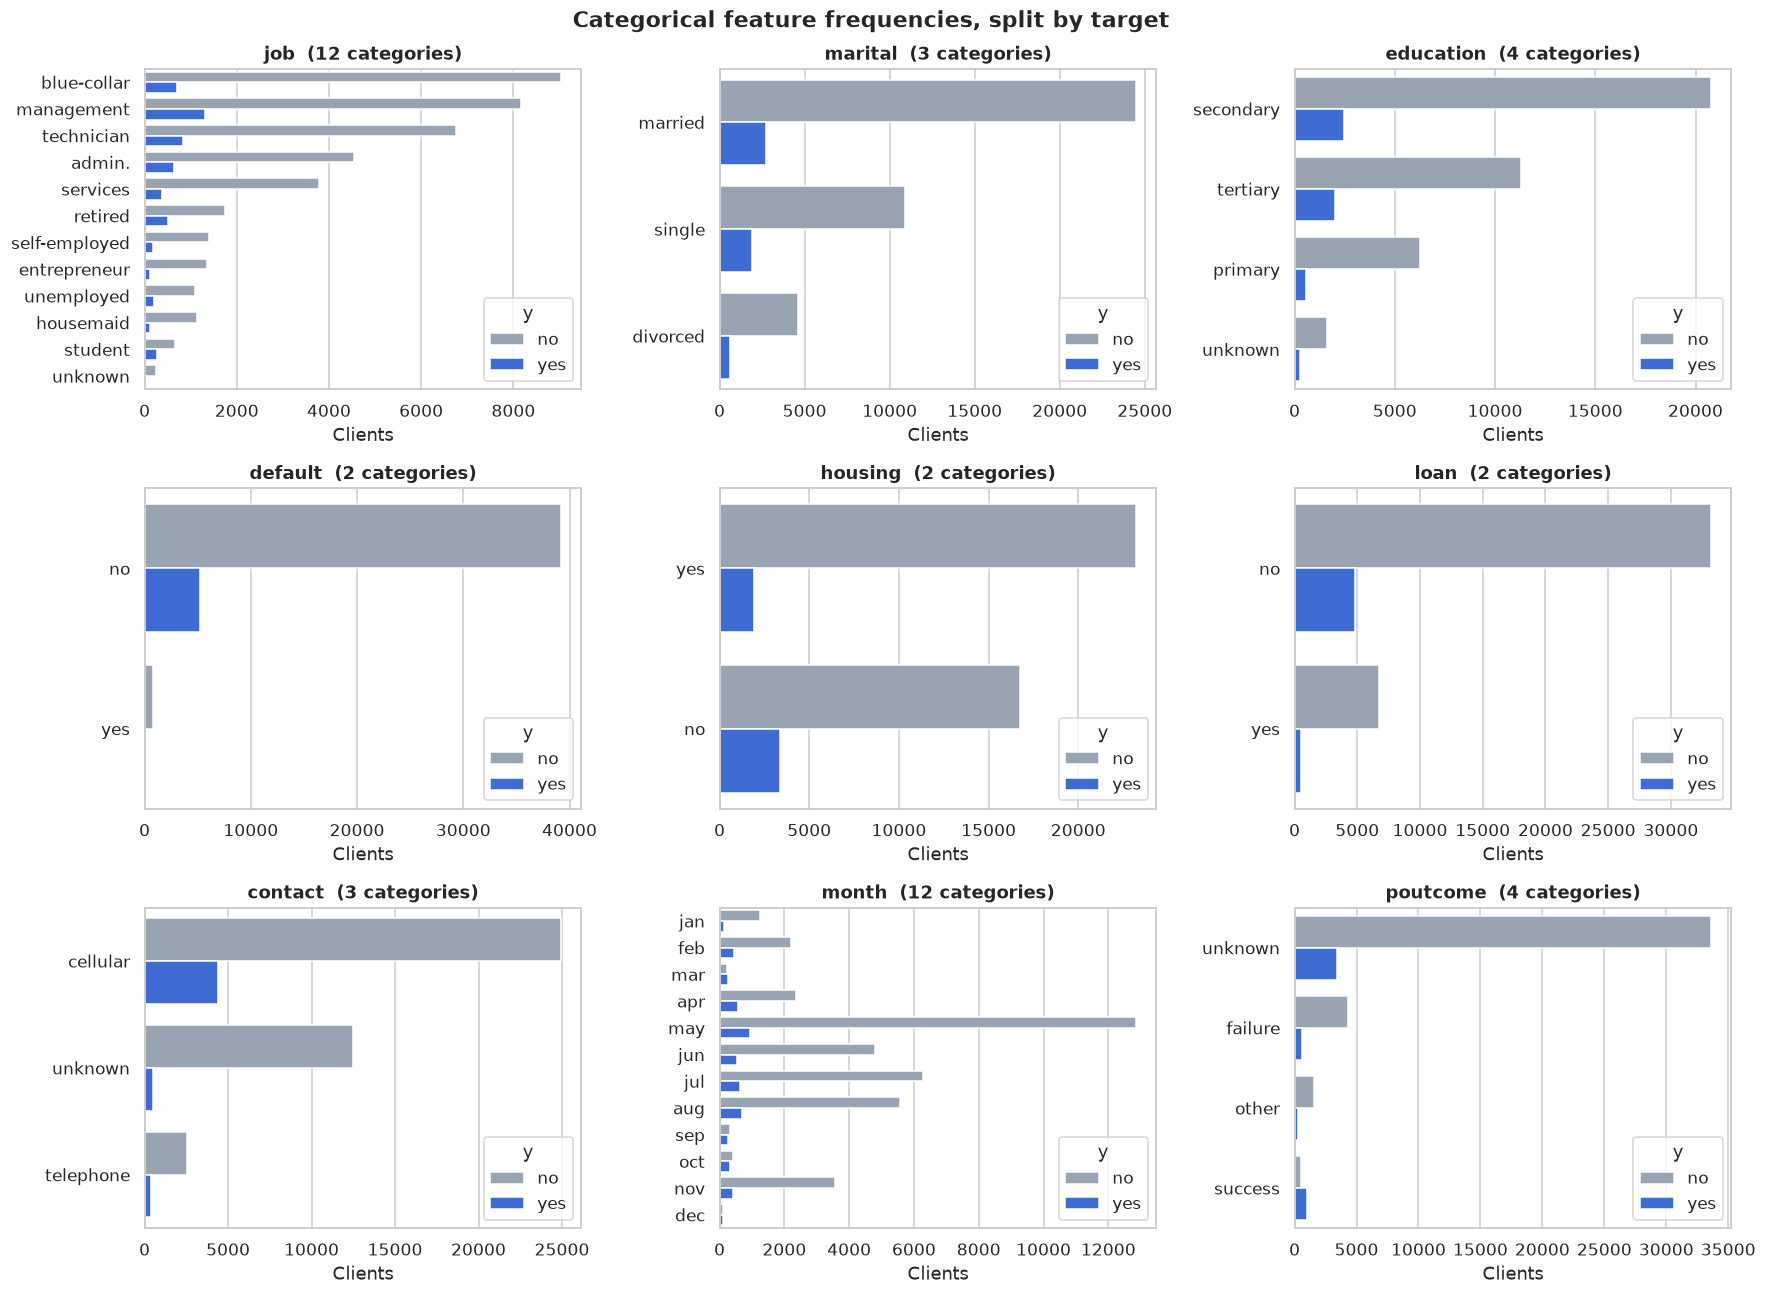

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, CATEGORICAL):
    order = MONTH_ORDER if col == "month" else df[col].value_counts().index
    sns.countplot(data=df, y=col, hue=TARGET, order=order, palette=PALETTE, ax=ax)
    ax.set_title(f"{col}  ({df[col].nunique()} categories)"); ax.set_xlabel("Clients"); ax.set_ylabel("")
    ax.legend(title="y", loc="lower right")
fig.suptitle("Categorical feature frequencies, split by target", fontweight="bold")
plt.tight_layout(); plt.show()

In [17]:
for col in CATEGORICAL:
    vc = df[col].value_counts()
    print(f"{col:<10} top: {vc.index[0]!r} ({vc.iloc[0] / len(df):.1%})   categories: {len(vc)}")

job        top: 'blue-collar' (21.5%)   categories: 12
marital    top: 'married' (60.2%)   categories: 3
education  top: 'secondary' (51.3%)   categories: 4
default    top: 'no' (98.2%)   categories: 2
housing    top: 'yes' (55.6%)   categories: 2
loan       top: 'no' (84.0%)   categories: 2
contact    top: 'cellular' (64.8%)   categories: 3
month      top: 'may' (30.4%)   categories: 12
poutcome   top: 'unknown' (81.7%)   categories: 4


### 7.2 Subscription rate by category

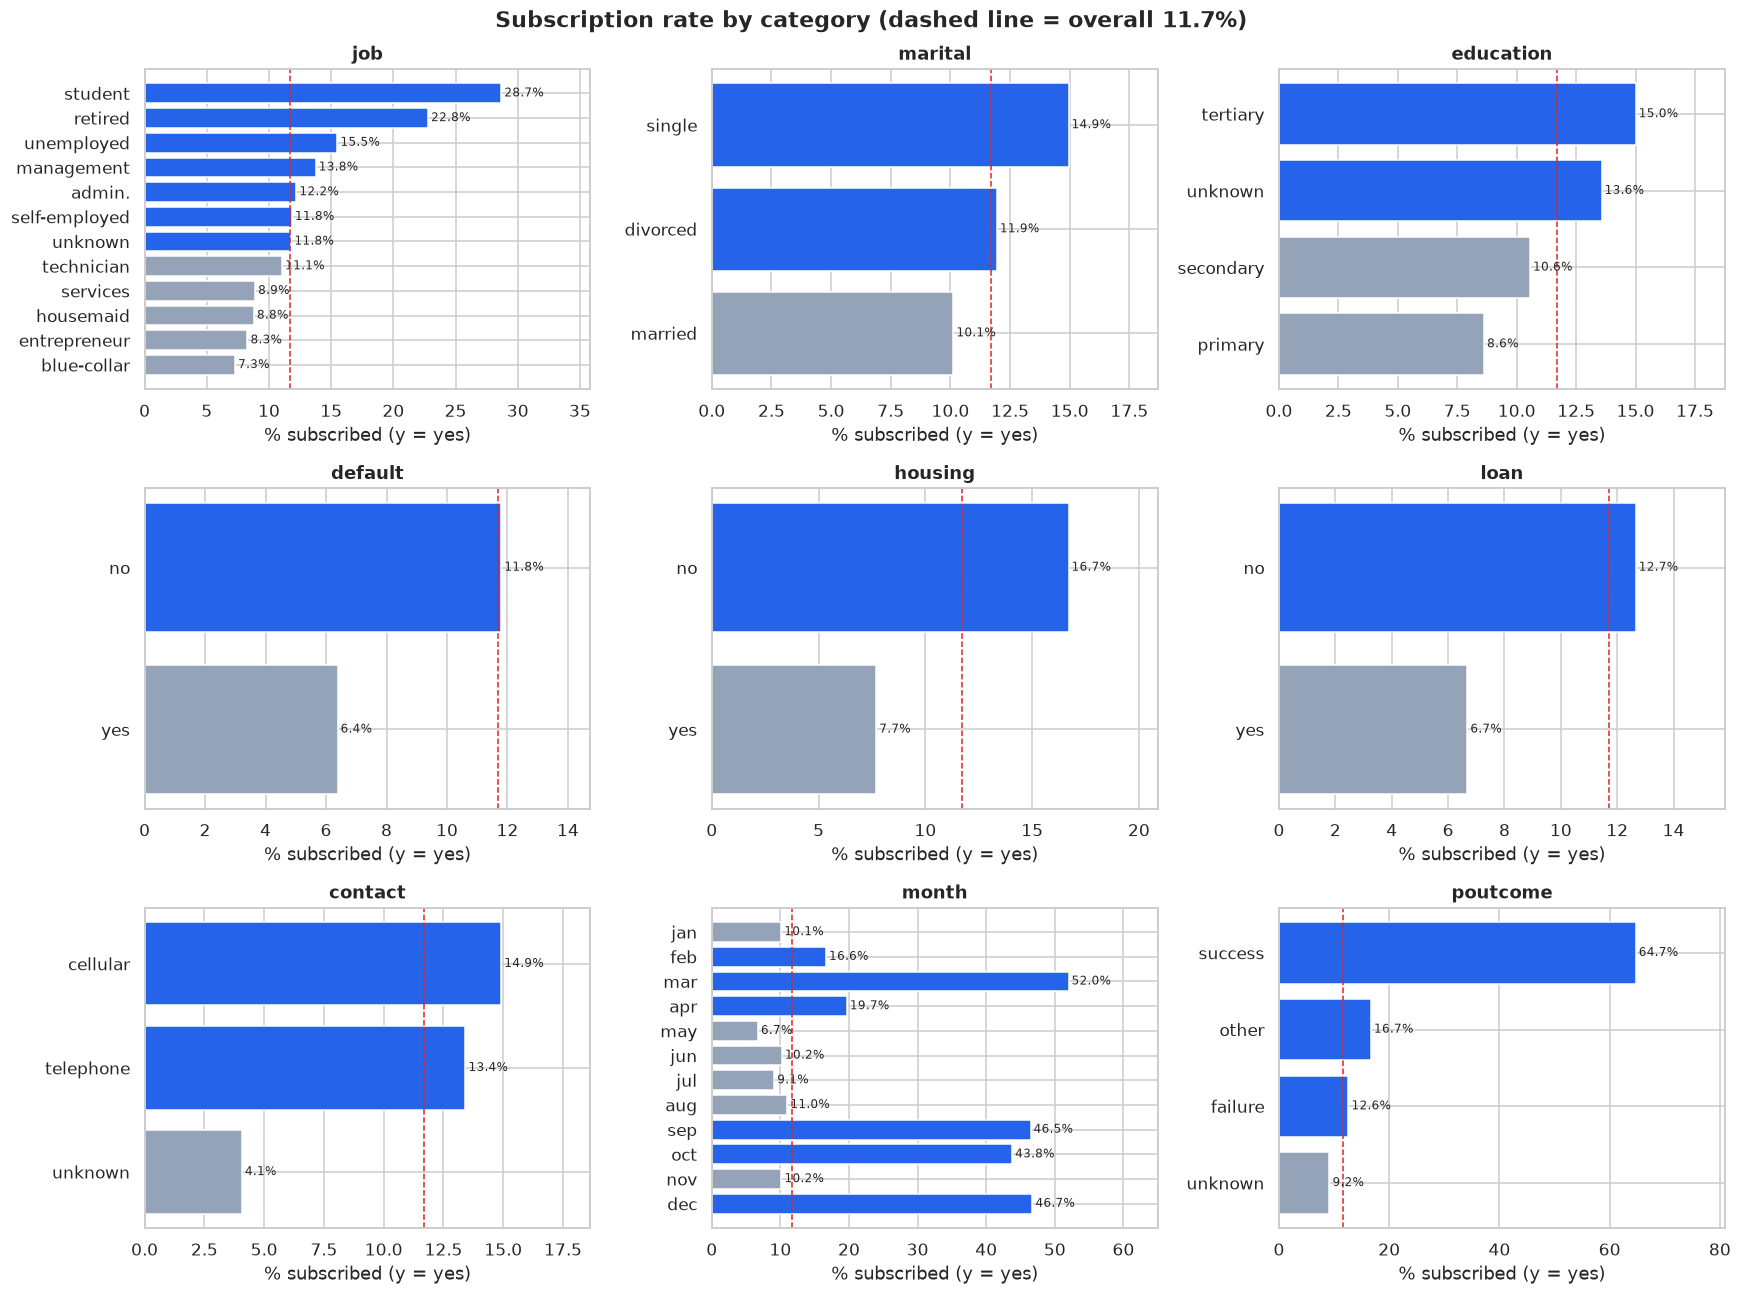

In [18]:
overall_rate = df[TARGET].eq("yes").mean() * 100
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, CATEGORICAL):
    rate = df.groupby(col)[TARGET].apply(lambda s: s.eq("yes").mean() * 100)
    rate = rate.reindex(MONTH_ORDER) if col == "month" else rate.sort_values()
    colors = [ACCENT if v >= overall_rate else "#94a3b8" for v in rate.values]
    bars = ax.barh(rate.index.astype(str), rate.values, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8)
    ax.axvline(overall_rate, color="#dc2626", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("% subscribed (y = yes)"); ax.set_xlim(0, rate.max() * 1.25)
    if col == "month":
        ax.invert_yaxis()  # jan at the top
fig.suptitle(f"Subscription rate by category (dashed line = overall {overall_rate:.1f}%)", fontweight="bold")
plt.tight_layout(); plt.show()

In [19]:
summary = []
for col in CATEGORICAL:
    rate = df.groupby(col)[TARGET].apply(lambda s: s.eq("yes").mean() * 100)
    summary.append({"feature": col, "highest": f"{rate.idxmax()} ({rate.max():.1f}%)",
                    "lowest": f"{rate.idxmin()} ({rate.min():.1f}%)", "spread_pp": round(rate.max() - rate.min(), 1)})
pd.DataFrame(summary).set_index("feature").sort_values("spread_pp", ascending=False)

,highest,lowest,spread_pp
feature,,,
poutcome,success (64.7%),unknown (9.2%),55.6
month,mar (52.0%),may (6.7%),45.3
job,student (28.7%),blue-collar (7.3%),21.4
contact,cellular (14.9%),unknown (4.1%),10.8
housing,no (16.7%),yes (7.7%),9.0
education,tertiary (15.0%),primary (8.6%),6.4
loan,no (12.7%),yes (6.7%),6.0
default,no (11.8%),yes (6.4%),5.4
marital,single (14.9%),married (10.1%),4.8


### 7.3 Age bands and contact history

,clients,yes_rate
age,,
18-25,1336,24.0
26-35,15571,12.0
36-45,13856,9.4
46-55,9548,9.4
56-65,4149,14.1
66-95,751,42.6


,clients,yes_rate_%
never contacted before (pdays = -1),36954,9.2
contacted in a previous campaign,8257,23.1


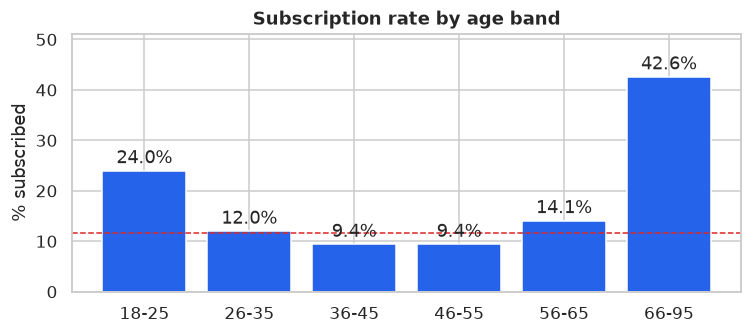

In [20]:
bands = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 65, 95], labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66-95"])
age_tbl = df.groupby(bands, observed=True)[TARGET].agg(clients="size", yes_rate=lambda s: round(s.eq("yes").mean() * 100, 1))
display(age_tbl)

hist_tbl = pd.DataFrame({
    "clients": [never.sum(), (~never).sum()],
    "yes_rate_%": [round(df.loc[never, TARGET].eq("yes").mean() * 100, 1), round(df.loc[~never, TARGET].eq("yes").mean() * 100, 1)],
}, index=["never contacted before (pdays = -1)", "contacted in a previous campaign"])
display(hist_tbl)

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(age_tbl.index.astype(str), age_tbl["yes_rate"], color=ACCENT)
ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.axhline(overall_rate, color="#dc2626", ls="--", lw=1)
ax.set_title("Subscription rate by age band"); ax.set_ylabel("% subscribed"); ax.set_ylim(0, age_tbl["yes_rate"].max() * 1.2)
plt.tight_layout(); plt.show()

**Observations (categorical):**
- **`poutcome`** is the strongest single signal. Clients whose previous campaign was a `success` subscribe at **64.7%**, versus 9.2% for `unknown` (no previous campaign).
- **`month`** has a large spread, and call volume is very uneven. `may` has the most calls (13,766) but the lowest rate (6.7%). The rare months `mar` (477 calls, 52.0%), `dec` (214, 46.7%), `sep` (579, 46.5%) and `oct` (738, 43.8%) convert far better. This suggests the campaign strategy changed over time.
- **`contact`**: `unknown` converts at only 4.1%, versus 14.9% for cellular and 13.4% for telephone. So "unknown" is informative, not noise.
- **`job`**: `student` (28.7%) and `retired` (22.8%) are highest; `blue-collar` (7.3%) is lowest, even though it is the most common job (9,732 clients).
- **Age** is U-shaped: 24.0% for 18–25 and 42.6% for 66–95, but around 9.4% for ages 36–55.
- **Loans and default**: clients *without* a housing loan (16.7% vs 7.7%), *without* a personal loan (12.7% vs 6.7%), and *not* in default (11.8% vs 6.4%) subscribe more often.
- **Education and marital status**: `tertiary` (15.0%) and `single` (14.9%) are somewhat higher.

**Decision.** All nine categorical features are **one-hot encoded** with `handle_unknown="ignore"`. The categories have no natural order (even `month` is better treated as nominal, given the uneven volumes), and a category that only appears in uploaded test data will then not crash the app.

## 8. Correlation heatmap

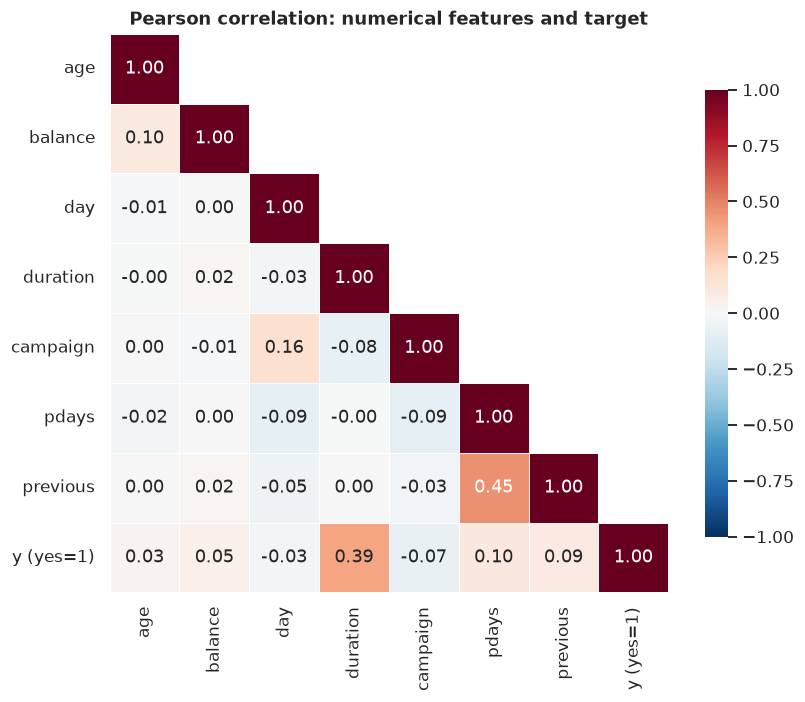

Correlation with target (y = yes):
duration    0.395
pdays       0.104
previous    0.093
balance     0.053
age         0.025
day        -0.028
campaign   -0.073


In [21]:
corr_df = df[NUMERICAL].copy()
corr_df["y (yes=1)"] = df[TARGET].eq("yes").astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation: numerical features and target"); ax.grid(False)
plt.tight_layout(); plt.show()

print("Correlation with target (y = yes):")
print(corr["y (yes=1)"].drop("y (yes=1)").sort_values(ascending=False).round(3).to_string())

**Observation.**
- No pair of numerical features is strongly collinear. The largest pair is `pdays`–`previous` at 0.455, because both encode "was the client contacted before". So no feature needs to be dropped for redundancy.
- `duration` has by far the highest correlation with the target (**0.395**), see Section 9. Among the features we keep, the highest are `pdays` (0.104) and `previous` (0.093); `campaign` is slightly negative (-0.073).
- The weak linear correlations suggest that much of the signal comes from the categorical features and from non-linear effects. This is a reason to compare linear (Logistic Regression) and non-linear (Decision Tree, KNN, RBF-SVM) models.

## 9. Why `duration` is excluded

,median,mean
y,,
no,164.0,221.2
yes,426.0,537.3


Calls with duration == 0 seconds: 3 (all with y = ['no'])


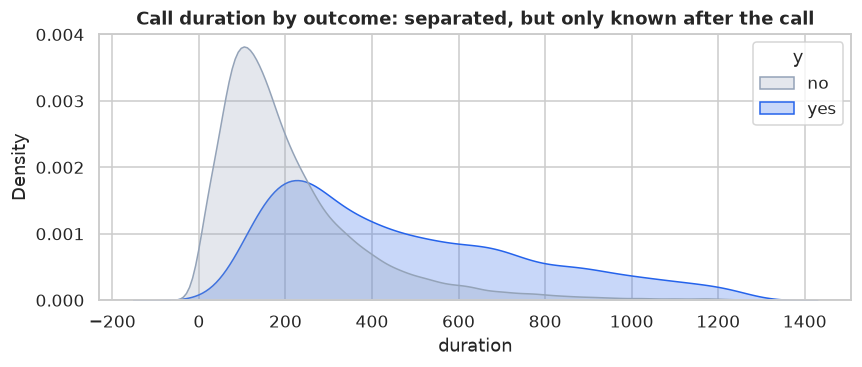

In [22]:
dur = df.groupby(TARGET)["duration"].agg(["median", "mean"]).round(1)
display(dur)
print(f"Calls with duration == 0 seconds: {(df['duration'] == 0).sum()} "
      f"(all with y = {df.loc[df['duration'] == 0, TARGET].unique().tolist()})")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.kdeplot(data=df[df["duration"] <= df["duration"].quantile(0.99)], x="duration", hue=TARGET,
            palette=PALETTE, common_norm=False, fill=True, ax=ax)
ax.set_title("Call duration by outcome: separated, but only known after the call")
plt.tight_layout(); plt.show()

`duration` is the length of the last call, in seconds. Subscribers' calls last much longer (median **426 s vs 164 s**), and its correlation with `y` (0.395) is about 4× that of any other numerical feature. **But the duration is only known *after* the call has ended, which is also when the outcome is known.** The UCI documentation itself notes that if `duration = 0` then `y = "no"`, and recommends discarding `duration` when building a realistic predictive model.

The goal is to decide *before* calling whom to call. Using `duration` would be **target leakage**: the model would look excellent on paper but could not be used in practice. We therefore **drop `duration`** and keep **15 input features** (6 numerical + 9 categorical), still above the assignment minimum of 12.

## 10. Observations and modelling implications

| # | Finding (from this notebook) | Consequence for modelling |
|---|---|---|
| 1 | 45,211 rows, 16 inputs, no NaN, no duplicates | Meets the size requirements; little cleaning needed |
| 2 | `"unknown"` in poutcome 81.75%, contact 28.80%, education 4.11%, job 0.64% | Keep as its own category; one-hot encode with `handle_unknown="ignore"`; imputers kept as a safety net |
| 3 | Target is 88.30% no / 11.70% yes | Stratified 80:20 split (`random_state=42`); `class_weight="balanced"` where supported; judge on MCC, F1, AUC, not accuracy (baseline 88.3%) |
| 4 | `balance`, `campaign`, `pdays`, `previous` are heavily skewed with many IQR outliers, but the values are genuine | Keep outliers; median-impute + StandardScaler (fitted on train only) for scale-sensitive models |
| 5 | Weak linear correlations; strongest signals are categorical (`poutcome` success 64.7%, `month`, `contact`) and non-linear (U-shaped age) | Compare linear and non-linear models; one-hot encoding is essential |
| 6 | `duration` correlates 0.395 with y but is only known after the call | **Excluded (target leakage)**, leaving 15 features |
| 7 | Mixed numerical and one-hot features; GaussianNB requires dense input | Dense one-hot output in the ColumnTransformer |

These choices are implemented in `src/preprocess.py` and `src/train.py`. To avoid leakage, every transformation is fitted inside a scikit-learn `Pipeline` on the training split only.